# TP 1 — Exploration d'un jeu de données : `clients.csv`
**Analyse de données — Master IA / Master RSD** · Chapitre 1 : Introduction à l'analyse de données

**Objectifs du TP**
1. Vérifier l'environnement Python (Pandas, NumPy, Matplotlib, Seaborn).
2. Passer des **données brutes** à une **information** puis à une **décision** (exemple du café).
3. Importer un fichier CSV et appliquer les *six commandes réflexes* d'exploration.
4. Repérer les **valeurs manquantes** et les **valeurs aberrantes**, puis formuler une **question métier**.
5. Pour aller plus loin : types de variables, SQL, visualisation, encodage et mise à l'échelle.

> Travail en binôme. Les cellules marquées **`# TODO`** sont à compléter. Les cellules **✅ Auto-correction** vérifient vos réponses : si elles affichent une erreur, corrigez la cellule précédente.

---
## Partie 1 — Vérifier l'installation
Si une bibliothèque manque, dans le terminal (Anaconda Prompt) :
```
conda activate data
pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

In [109]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Python  :", sys.version.split()[0])
print("pandas  :", pd.__version__)
print("numpy   :", np.__version__)
print("seaborn :", sns.__version__)

Python  : 3.13.2
pandas  : 3.0.6
numpy   : 2.3.4
seaborn : 0.13.2


---
## Partie 2 — Échauffement : des données brutes à la décision
Reprenons l'exemple du cours : les ventes d'un café sur une semaine ($n = 7$ individus, $p = 2$ variables).

**Données brutes → Analyse → Décision**

In [110]:
cafe = pd.DataFrame({
    "jour":     ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"],
    "boissons": [45, 52, 38, 60, 55, 70, 40],
    "recette":  [180, 208, 152, 240, 220, 280, 160],   # en DA
})
cafe

,jour,boissons,recette
0,Lundi,45,180
1,Mardi,52,208
2,Mercredi,38,152
3,Jeudi,60,240
4,Vendredi,55,220
5,Samedi,70,280
6,Dimanche,40,160


**Questions**
1. Total des boissons vendues et total des recettes.
2. Moyenne quotidienne des boissons vendues (arrondie à 0,1).
3. Le jour le plus rentable.
4. Quelle **décision** proposeriez-vous au gérant ?

In [111]:
total_boissons = cafe.boissons.sum()
total_recette  = cafe.recette.sum()
moyenne_jour   = round(cafe.boissons.mean(),ndigits=1) 
meilleur_jour  = cafe.loc[cafe['recette'].idxmax()].jour
print(total_boissons, total_recette, moyenne_jour, meilleur_jour)

360 1440 51.4 Samedi


✅ **Auto-correction**

In [112]:
assert total_boissons == 360, "Total des boissons attendu : 360"
assert total_recette == 1440, "Total des recettes attendu : 1440 DA"
assert moyenne_jour == 51.4, "Moyenne attendue : 51.4 boissons/jour"
assert meilleur_jour == "Samedi", "Le jour le plus rentable est le samedi"
print("✅ Partie 2 correcte")

✅ Partie 2 correcte


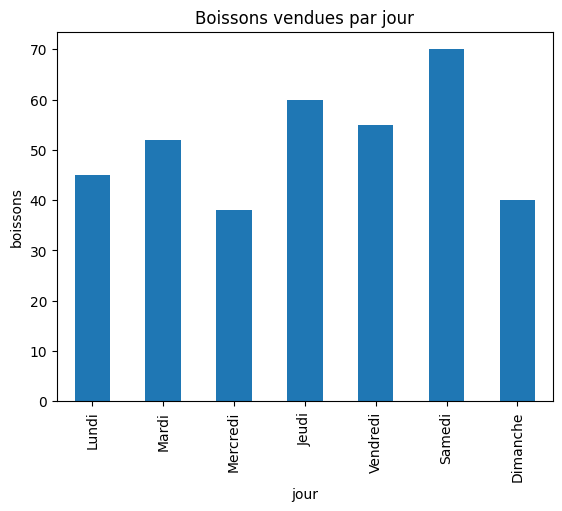

In [113]:
# Visualiser pour convaincre : le week-end se détache-t-il ?
cafe.plot.bar(x="jour", y="boissons", legend=False, title="Boissons vendues par jour")
plt.ylabel("boissons")
plt.show()

✍️ **Votre décision :** *(double-cliquez pour écrire)*

…

---
## Partie 3 — Exercice guidé : explorer `clients.csv`
Jeu de données **fictif** : 1 000 clients, 8 variables. Cinq étapes, dans l'ordre.

### Étape 1 — Importer le fichier
Le fichier utilise le séparateur **`;`** (convention des CSV français) et l'encodage **utf-8**.

In [114]:
df = pd.read_csv('clients.csv', sep = ';', encoding='utf-8')

df.head()

,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
0,1,18,49200.0,2,3,7,client0001@exemple.dz,C
1,2,87,54900.0,3,10,12,client0002@exemple.dz,A
2,3,55,40200.0,1,13,17,client0003@exemple.dz,A
3,4,67,31600.0,1,11,3,client0004@exemple.dz,C
4,5,40,60300.0,0,13,17,client0005@exemple.dz,A


### Étape 2 — Dimensions et types
Utilisez `shape` et `dtypes`. Combien de colonnes numériques ? Combien de catégorielles ?

In [115]:
# afficher la forme du DataFrame
print(df.shape)
# afficher le type de chaque colonne
print(df.dtypes)

(1000, 8)
id              int64
age             int64
revenu        float64
nb_enfants      int64
anciennete      int64
nb_achats       int64
email             str
segment           str
dtype: object


In [116]:
nb_numeriques   = df.select_dtypes(include='number').shape[1]
nb_categorielles = df.select_dtypes(include='str').shape[1] # (indice : include="object")
print(nb_numeriques, nb_categorielles)

6 2


✅ **Auto-correction**

In [117]:
assert df.shape == (1000, 8), f"Dimensions attendues (1000, 8), obtenu {df.shape} -> vérifiez le séparateur à l'étape 1"
assert (nb_numeriques, nb_categorielles) == (6, 2), "Attendu : 6 numériques, 2 catégorielles"
print("✅ Étape 2 correcte")

✅ Étape 2 correcte


### Étape 3 — Valeurs manquantes
Utilisez `info()` puis `isna().sum()`.

In [118]:
# TODO : df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1000 non-null   int64  
 1   age         1000 non-null   int64  
 2   revenu      963 non-null    float64
 3   nb_enfants  1000 non-null   int64  
 4   anciennete  1000 non-null   int64  
 5   nb_achats   1000 non-null   int64  
 6   email       1000 non-null   str    
 7   segment     1000 non-null   str    
dtypes: float64(1), int64(5), str(2)
memory usage: 62.6 KB


In [119]:
manquants = df.isna().sum().sort_values(ascending=False) # TODO : nombre de NaN par colonne, trié par ordre décroissant
manquants

revenu        37
id             0
age            0
nb_enfants     0
anciennete     0
nb_achats      0
email          0
segment        0
dtype: int64

✅ **Auto-correction**

In [120]:
assert manquants["revenu"] == 37, "37 valeurs manquantes attendues dans revenu"
assert manquants.drop("revenu").sum() == 0, "Les autres colonnes ne doivent pas avoir de NaN"
print("✅ Étape 3 correcte")

✅ Étape 3 correcte


### Étape 4 — Statistiques descriptives et effectifs par segment

In [121]:
# TODO : statistiques descriptives de toutes les colonnes (numériques ET catégorielles)
df.describe(include='all')

,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
count,1000.000000,1000.000000,963.000000,1000.000000,1000.000000,1000.000000,1000,1000
unique,NaN,NaN,NaN,NaN,NaN,NaN,1000,3
top,NaN,NaN,NaN,NaN,NaN,NaN,client0001@exemple.dz,A
freq,NaN,NaN,NaN,NaN,NaN,NaN,1,412
mean,500.500000,41.868000,45706.956386,1.440000,10.463000,8.813000,NaN,NaN
std,288.819436,11.738158,38330.349749,1.189881,6.087832,4.223016,NaN,NaN
min,1.000000,18.000000,9600.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,250.750000,33.000000,28650.000000,1.000000,5.000000,6.000000,NaN,NaN
50%,500.500000,42.000000,39900.000000,1.000000,11.000000,8.000000,NaN,NaN
75%,750.250000,50.000000,56250.000000,2.000000,16.000000,12.000000,NaN,NaN


In [122]:
effectifs = df['segment'].value_counts() # TODO : value_counts sur la colonne segment
effectifs

segment
A    412
B    321
C    267
Name: count, dtype: int64

✅ **Auto-correction**

In [123]:
assert effectifs.idxmax() == "A" and effectifs.max() == 412, "Segment majoritaire attendu : A (412 clients)"
print("✅ Étape 4 correcte")

✅ Étape 4 correcte


### Étape 5 — Une anomalie et une question métier
Comparez le **maximum** du revenu avec son **99ᵉ centile**. Que constatez-vous ?

In [124]:
revenu_max = df.revenu.max()   # TODO
revenu_p99 = df.revenu.quantile(q=0.99)   # TODO (quantile)
print(revenu_max, revenu_p99)

999999.0 117590.0


✅ **Auto-correction**

In [125]:
assert revenu_max == 999999, "Le revenu maximum attendu est 999 999"
assert revenu_p99 < 150000, "Le 99e centile doit être très inférieur au maximum"
print("✅ Étape 5 correcte")

✅ Étape 5 correcte


In [126]:
# Qui est ce client ?
df[df["revenu"] > 200000]

,id,age,revenu,nb_enfants,anciennete,nb_achats,email,segment
797,798,46,999999.0,1,9,6,client0798@exemple.dz,C


✍️ **Anomalie repérée :** there exists an outlier in the data. 

✍️ **Question métier qu'elle soulève :** …

---
## Partie 4 — Pour aller plus loin
### 4.1 Types de variables
Pour chaque colonne, indiquez son type : **continue**, **discrète**, **nominale** ou **ordinale** (voir le cours, section 2). Que pensez-vous de `id` ?

In [127]:
types_variables = {
    "id": 'discrete',           # TODO
    "age": 'discrete', 
    "revenu": 'continuous',
    "nb_enfants": 'discrete',
    "anciennete": 'discrete',
    "nb_achats": 'discrete',
    "email": 'nominal',
    "segment": 'nominal',
}

### 4.2 Interroger les données avec SQL
On charge le DataFrame dans une base SQLite **en mémoire**, puis on exécute la requête du cours.

In [128]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("clients", conn, index=False)

requete = """
SELECT   segment, AVG(revenu) AS revenu_moyen, COUNT(*) AS nb_clients
FROM     clients
GROUP BY segment
ORDER BY revenu_moyen DESC;
"""
pd.read_sql(requete, conn)

,segment,revenu_moyen,nb_clients
0,A,55924.937028,412
1,B,39289.102564,321
2,C,37619.681102,267


**À faire :** obtenez le **même résultat avec Pandas** (`groupby`), puis refaites le calcul **en excluant le revenu aberrant**. Quel segment est le plus affecté ?

In [129]:
# TODO : revenu moyen par segment avec groupby
print(df.groupby('segment')['revenu'].mean())
# TODO : même calcul en excluant revenu > 200000 (clause WHERE en SQL, filtre booléen en Pandas)
df[df['revenu'] <= 200000].groupby('segment')['revenu'].mean()


segment
A    55924.937028
B    39289.102564
C    37619.681102
Name: revenu, dtype: float64


segment
A    55924.937028
B    39289.102564
C    33815.810277
Name: revenu, dtype: float64

### 4.3 Visualiser la distribution du revenu
Tracez un **histogramme** du revenu et un **boxplot** du revenu par segment. L'anomalie est-elle visible ?

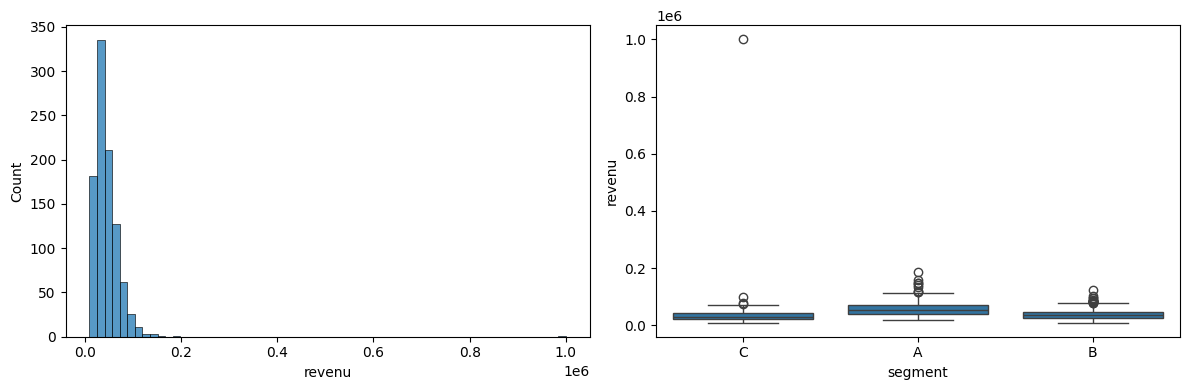

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# TODO : sns.histplot(...) sur axes[0]
sns.histplot(data=df, x='revenu', ax=axes[0])
# TODO : sns.boxplot(...) sur axes[1], x="segment", y="revenu"
sns.boxplot(data=df, x='segment',y='revenu', ax=axes[1])
plt.tight_layout()
plt.show()

### 4.4 Encodage et mise à l'échelle
Rappel du cours : une variable **quantitative** se met à l'échelle ; une variable **qualitative** s'**encode**.
1. Encodez `segment` en **one-hot** avec `pd.get_dummies`.
2. Normalisez `age` en **Min-Max** : $\dfrac{x - \min}{\max - \min}$ et standardisez-le en **Z-score** : $\dfrac{x - \bar{x}}{\sigma}$.

In [131]:
segment_onehot = pd.get_dummies(df['segment']) # TODO
age_minmax     = (df["age"] - df["age"].min()) / (df["age"].max() - df["age"].min()) # TODO
age_zscore     = (df["age"] - df['age'].mean())/df['age'].std()   # TODO
print(segment_onehot.shape)

(1000, 3)


✅ **Auto-correction**

In [132]:
assert segment_onehot.shape == (1000, 3), "Une colonne par modalité : A, B, C"
assert age_minmax.min() == 0 and age_minmax.max() == 1, "Min-Max doit donner des valeurs entre 0 et 1"
assert abs(age_zscore.mean()) < 1e-9 and abs(age_zscore.std() - 1) < 1e-9, "Z-score : moyenne 0, écart-type 1"
print("✅ Partie 4.4 correcte")

✅ Partie 4.4 correcte


---
## Bilan
| Étape | Commande | Ce qu'on a appris |
|---|---|---|
| Import | `read_csv(sep=";")` | le séparateur conditionne tout |
| Dimensions / types | `shape`, `dtypes` | 1000 × 8, 6 numériques, 2 catégorielles |
| Manquants | `info()`, `isna().sum()` | 37 revenus manquants |
| Statistiques | `describe()`, `value_counts()` | segment A majoritaire (412) |
| Anomalie | `max()`, `quantile(0.99)` | 999 999 DA → à investiguer avant toute analyse |

> **À retenir :** on n'analyse jamais un jeu de données avant de l'avoir **exploré** : dimensions, types, valeurs manquantes, valeurs aberrantes.